# Single Reservoir

In [100]:
from dataclasses import dataclass 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import scipy.stats as sp_stats
from scipy.stats import norm, skew
import pandas as pd

| **Parameter**          | **Description**             | **Units** | **Constraints**                                | **Role in the Model**                                                                        |
| ---------------------- | --------------------------- | --------- | ---------------------------------------------- | -------------------------------------------------------------------------------------------- |
| **`A`**                | Catchment Area              | $m^2$     | $> 0$                                          | Scales the total precipitation collected by the surrounding basin.                           |
| **`B`**                | Seepage Coefficient         | $m/s$     | $\ge 0$                                        | Determines how much water leaks into the groundwater/soil.                                   |
| **`P`**                | Precipitation Rate          | $m/s$     | $\ge 0$                                        | The baseline average rainfall driving water into the system.                                 |
| **`E`**                | Evaporation Rate            | $m/s$     | $\ge 0$ (usually $< P$)                        | The baseline rate at which surface water evaporates into the atmosphere.                     |
| **`Phi` ($\Phi$)**     | Runoff / Pumped Fraction    | None      | $0 \le \Phi \le 1$                             | The percentage of precipitation diverted, pumped, or lost before it can enter the reservoir. |
| **`alpha` ($\alpha$)** | Scaling Exponent (Inflow)   | None      | $> 0$                                           | Relates the physical water volume to the effective surface area receiving rainfall.          |
| **`beta` ($\beta$)**   | Scaling Exponent (Outflow)  | None      | $> 0$                                          | Relates water volume to the discharge rate (e.g., how fast water leaves the spillway).       |
| **`gamma` ($\gamma$)** | Scaling Exponent (Seepage)  | None      | $> 0$                                          | Relates water volume to groundwater seepage rates based on lakebed pressure/geometry.        |
| **`sigma_1`**          | Precipitation Noise         | None      | $> 0$                                          | The volatility/intensity of random fluctuations in rainfall.                                 |
| **`sigma_2`**          | Evaporation Noise           | None      | $> 0$                                          | The volatility of random fluctuations in evaporation (due to wind/temperature).              |
| **`sigma_3`**          | Catchment Noise             | None      | $> 0$                                          | The volatility of random fluctuations in the basin runoff or pumping efficiency.             |
| **`c`, `e`**           | $\psi(X)$ Scaling Constants | Varies    | Case dependent                                 | Modifiers used to define the lake's surface-area-to-volume ratio in Case III.                |
| **`a_p`, `b_p`**       | $\psi(X)$ Geometric Bounds  | None      | Case dependent                                 | Defines the extreme boundaries of the surface area ratio in the mathematical proofs.         |
| **`n`**                | $\psi(X)$ Polynomial Degree | None      | Integer $\ge 1$                                | Dictates whether the lake's banks slope linearly ($n=1$), quadratically ($n=2$), etc.        |


In [5]:
@dataclass
class Hydrology:
    A: float  = 1 # Area of the catchment (m^2)
    B: float  = 0 # Seepage coefficient (m/s)

    P: float  = 1 # Precipitation rate (m/s)
    E: float  = 0.1 # Evaporation rate (m/s)
    Phi: float  = 0.7 # Percentage pumped out

    alpha: float  = 1 # Shape scaling exponent
    beta: float  = 1 # Shape scaling exponent
    gamma: float  = 1 # Shape scaling exponent

    sigma_1: float  = 0.1 # Standard deviation of the first noise term
    sigma_2: float  = 0.1 # Standard deviation of the second noise term
    sigma_3: float  = 0.1 # Standard deviation of the third noise term

    # For Psi
    c: float  = 0 # Constant in Psi
    e: float  = 0.1 # Constant in Psi
    a_p: float  = 1 # Constant in Psi
    b_p: float  = 1 # Constant in Psi
    n: float  = 1 # Constant in Psi

$$\psi(X) = c + e\left(\frac{X}{a_p}\right)^{\frac{n}{b_p}}$$

In [6]:
def psi(X, p: Hydrology):
    """
    This represents the ratio of the surface area of the surrounding land (catchment) to the surface 
    area of the reservoir itself.
    """
    return (p.c + p.e * (X / p.a_p) ** (p.n / p.b_p))

$$\psi'(X) = \frac{n \cdot e}{b_p \cdot a_p^{n/b_p}} X^{\frac{n-b_p}{b_p}}$$

In [7]:
def psi_prime(X, p: Hydrology):
    """
    This represents the derivative of the ratio of the surface area of the surrounding land (catchment) to the surface area of the reservoir itself with respect to X. 
    """
    return (p.e * (p.n / p.b_p) * (1 / p.a_p) ** (p.n / p.b_p) * X ** ((p.n / p.b_p) - 1))

$$F(x) = A x^\alpha \Big[ P(1 - \Phi) + \psi(x)(P\Phi - E) \Big] - Ax^\beta - Bx^\gamma$$
$$F_1 = P(1 - \Phi) + \psi(X)(P\Phi - E)$$

$$F_2 = -A X^\beta - B X^\gamma$$

$$F(X) = A X^\alpha F_1 + F_2$$

In [8]:
def F(X, p: Hydrology):
    """
    This function calculates the deterministic part of the reservoir level change, considering precipitation, evaporation, and seepage. 
    """
    psi_x = psi(X, p)
    F1 = p.P * (1 - p.Phi) + psi_x * (p.P * p.Phi - p.E)
    F2 = -p.A * X**p.beta - p.B * X**p.gamma
    return (p.A*X**p.alpha * F1 + F2)

The Diffusion Terms:
1. $$g_1(X) = A \sigma_1 X^\alpha (1 - \Phi + \Phi\psi(X))$$
2. $$g_2(X) = -A \sigma_2 X^\alpha \psi(X)$$
3. $$g_3(X) = -A \sigma_3 P X^\alpha (1 - \psi(X))$$

In [9]:
def Calculate_g(X, p: Hydrology):
    """
    This function calculates the stochastic part of the reservoir level change, considering three independent noise terms.
    """
    psi_x = psi(X, p)
    g1 = p.A * p.sigma_1 * X**p.alpha * (1 - p.Phi + psi_x * p.Phi)
    g2 = - p.A * p.sigma_2 * X**p.alpha * psi_x
    g3 = - p.A * p.sigma_3 *p.P * X**p.alpha * (1 - psi_x) 
    return [g1, g2, g3]

The Derivatives:
1. $$g_1'(X) = A \sigma_1 \left[ \alpha X^{\alpha-1} (1 - \Phi + \Phi\psi(X)) + X^\alpha \Phi \psi'(X) \right]$$
2. $$g_2'(X) = -A \sigma_2 \left[ \alpha X^{\alpha-1} \psi(X) + X^\alpha \psi'(X) \right]$$
3. $$g_3'(X) = -A \sigma_3 P \left[ \alpha X^{\alpha-1} (1 - \psi(X)) - X^\alpha \psi'(X) \right]$$

In [10]:
def Calculate_g_prime(X, p: Hydrology):
    """
    This function calculates the derivatives of the stochastic part of the reservoir level change with respect to X, considering three independent noise terms. 
    """
    psi_x = psi(X, p)
    psi_prime_x = psi_prime(X, p)
    g1_prime = p.A * p.sigma_1 * (p.alpha * X**(p.alpha - 1) * (1 - p.Phi + psi_x * p.Phi) + X**p.alpha * psi_prime_x * p.Phi)
    g2_prime = - p.A * p.sigma_2 * (p.alpha * X**(p.alpha - 1) * psi_x + X**p.alpha * psi_prime_x)
    g3_prime = - p.A * p.sigma_3 * p.P * ((p.alpha * X**(p.alpha - 1) * (1 - psi_x) - X**p.alpha * psi_prime_x))
    return [g1_prime, g2_prime, g3_prime]

In standard ODEs, the drift is just $F(X)$. But because we are converting a Stratonovich SDE to an Itô SDE for our numerical solver, we have to add the noise-induced drift correction (also called the Stratonovich correction).The formula for the total Itô drift is:
$$\text{Drift}(X) = F(X) + \frac{1}{2} \sum_{i=1}^{3} g_i(X)g_i'(X)$$

In [11]:
def Drift(X, p: Hydrology):
    """
    This function calculates the drift term of the stochastic differential equation, which is the sum of the deterministic part and a correction term that accounts for the stochastic part. 
    """
    g_vals = Calculate_g(X, p)
    g_prime_vals = Calculate_g_prime(X, p)
    corrected_term = (1/2) * sum(g_val * g_prime_val for g_val, g_prime_val in zip(g_vals, g_prime_vals))
    return F(X, p) + corrected_term

**Updation Rule for Euler Maruyama**

$$X_{next} = X_{prev} + \text{Drift}(X_{prev}) \cdot dt + g_1(X_{prev})dW_1 + g_2(X_{prev})dW_2 + g_3(X_{prev})dW_3$$

In [12]:
def EulerMaruyama(X0, p: Hydrology, T, N, M):
    """
    This function implements the Euler-Maruyama method to simulate the stochastic differential equation governing the reservoir level. 
    """
    dt = T / N
    X = np.zeros((N, M))
    X[0, :] = X0
    sqrt_dt = np.sqrt(dt)
    floor_val = 1e-8

    for i in range(1, N):
        X_prev = X[i - 1, :]

        # Noise terms for the three independent Brownian motions
        dW1, dW2, dW3 = np.random.normal(loc=0.0, scale=sqrt_dt, size=(3, M))

        # Drift and diffusion terms
        drift = Drift(X_prev, p)
        g_vals = Calculate_g(X_prev, p)

        # Updation step From Euler-Maruyama method
        X[i, :] = X_prev + drift * dt + g_vals[0] * dW1 + g_vals[1] * dW2 + g_vals[2] * dW3
        X[i, :] = np.maximum(X[i, :], floor_val)

    return X

In [13]:
def plot_simulation(X, T, N):
    time = np.linspace(0, T, N)
    plt.figure(figsize = (10,8))
    plt.plot(time, X[:,:10], color = 'grey', alpha=0.5)  # Plotting first 10 sample paths
    mean_path = np.mean(X, axis=1)
    plt.plot(time, mean_path, color='blue', label='Mean Path', linewidth=2)

    plt.title('Euler-Maruyama Simulation of Stochastic Hydrology Model')
    plt.xlabel('Time')
    plt.ylabel('Reservoir Level (X)')
    plt.legend()
    plt.grid()
    plt.show()

In [14]:
P = Hydrology()
T = 10
N = 1000  # Number of time steps
M = 100  # Number of sample paths
X0 = 0.5  # Initial reservoir level

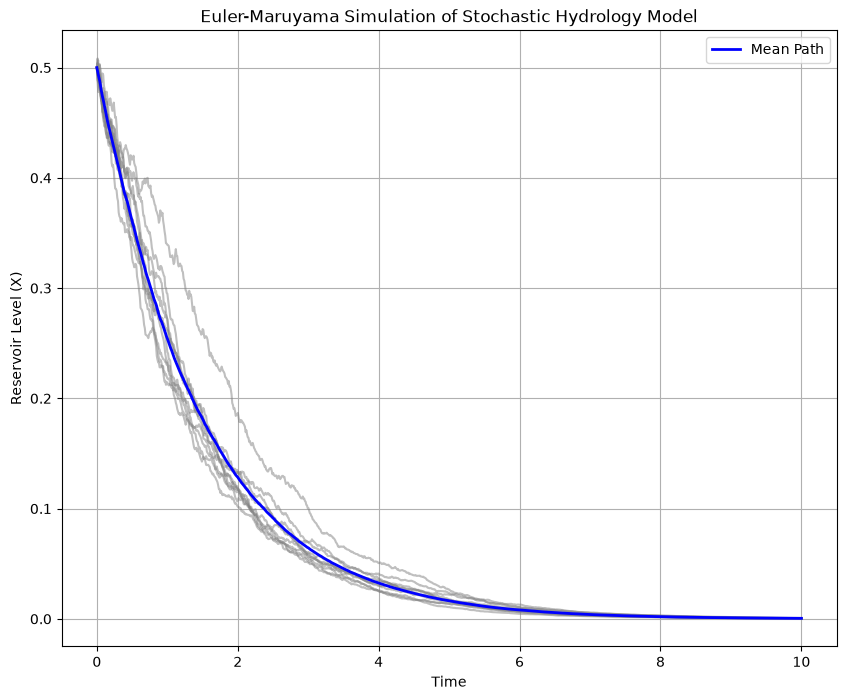

In [15]:
X_paths = EulerMaruyama(X0, P, T, N, M)
plot_simulation(X_paths, T, N)

# Analysis 
Given by the paper by STOCHASTIC NATURE OF OUTPUTS FROM CONCEPTUAL RESERVOIR MODEL CASCADES T.E. UNNY* and KARMESHU. To validate the numerical solution and demonstrate its felxibility of different conditions of the model, we will simulate 3 different scenarios.
## Case I
- The reservoir covers the entire catchment area
- **Validation**:- Histogram of numerical solution vs Exact Solution (Fokker-Planckk Gaussian Overlay)

## Case II
- The reservoir has almost zero surface area
- **Validation**:- Empirical Histogram vs Exact FP Guassian Overlay
## Case III
- The reservoir surface are scales linearly with the water volume. (The scaling factor $a$)
- **Validation**:- Empirical Histogram analyssi

# Fokker-Planck Equation
For the different Cases the authors used Fokker-Planck Equation to prove the the final probabilities simplify into Gaussian bell curve. Fokker-Planck equation is a formula thaht calculates the exact probability distribution of a system epxerincing random noise. It calculates the overall probability of the reservoir holding any specific water level once the system reaches a steady state.

# Case I
Reservoir covers the whole catchment

A is set to 1 to represent the reservoir covering the entire catchment are. Phi is set 0 to since the no land there is no land where the water can go
Looks at a graph for the final steady state water level over many simulations.
- X - Axis represent the Reservoir Outflow/water level and Y- Axis represent the probability Density.


| **Parameter** | **Value**      | **Reason for Value**                                                   |
| ------------- | -------------- | ---------------------------------------------------------------------- |
| `c`           | 1.0            | The reservoir covers the entire catchment area.                        |
| `e`           | 0.0            | The surface area ratio does not change since it already cover the area |
| `Phi`         | 0.0            | 0 since no land to absorb water                                        |
| `sigma_3`     | 0.0            | no noise here                                                          |
| `P`           | 1.0            | baseline value given in the paper                                      |
| `E`           | 0.1            | baseline value given in the paper                                      |
| `sigma_1`     | 1.0            | derived from variance                                                  |
| `sigma_2`     | `np.sqrt(0.1)` | derived from variancd                                                  |


In [73]:
def fp_validate(X, p: Hydrology, case):
    final_path = X[-1, :]
    plt.figure(figsize = (10,8))
    plt.hist(final_path, bins=40, density = True, alpha = 0.5, color = 'grey',
             edgecolor = 'black', label = 'Euler Maruyama Method')
    # Different cases
    if case == "I":
        theoretical_mean = p.P - p.E
        theoretical_var = 0.55 * p.a_p
    elif case == "II":
        theoretical_mean = (1 - p.Phi) * p.P
        theoretical_var = 0.095 * p.a_p
    else:
        print("Invali Input")

    theoretical_std = np.sqrt(theoretical_var)
    x_axis = np.linspace(min(final_path), max(final_path), 100)
    fp_pdf = sp.stats.norm.pdf(x_axis, theoretical_mean, theoretical_std)
    
    plt.plot(x_axis, fp_pdf, color='blue', linewidth=2, label='Fokker-Planck (Theoretical)')
    plt.title(f'Steady-State Distribution: Case {case}')
    plt.xlabel('Reservoir Outflow (X)')
    plt.ylabel('Probability Density')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

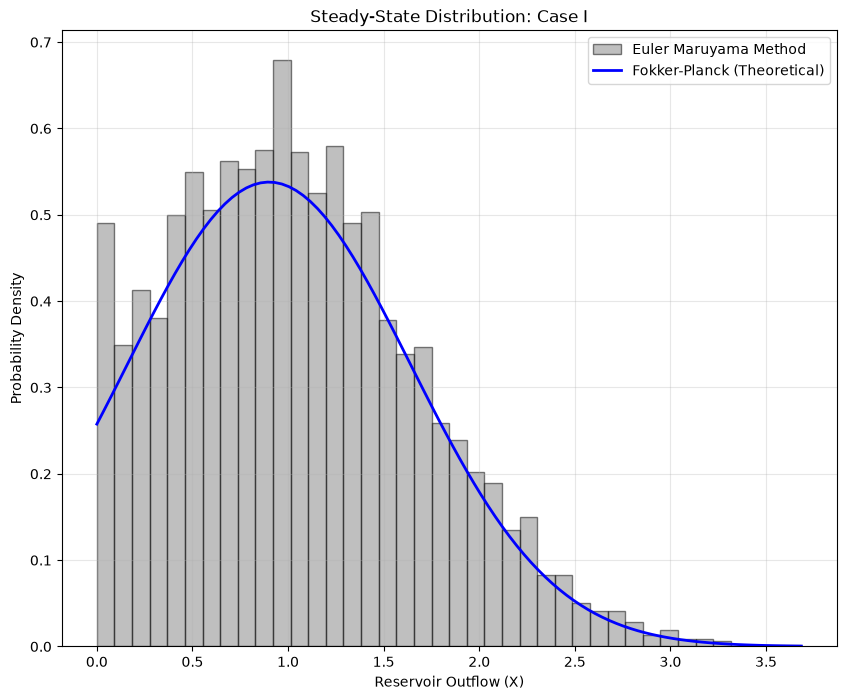

In [74]:
p_case1 = Hydrology(
    c=1.0, e=0.0, Phi=0.0, sigma_3=0.0,  
    P=1.0, E=0.1, a_p=1.0,               
    sigma_1=1.0, 
    sigma_2=np.sqrt(0.1),                # UPDATED: \sigma_E^2 = 0.1
    alpha=0.0, beta=1.0, gamma=1.0,      
    A=1.0, B=0.0                         
)
# Run simulation
X = EulerMaruyama(X0=0.5, p=p_case1, T=10.0, N=1000, M=5000)

# Plot validation
fp_validate(X, p_case1, case="I")

# Case II

The reservoir has almost zero surface are.


A is set near 0 to represent almost no surface area. and phi is set to 0.5 which lowers the eman


| **Parameter** | **Value**      | **Reason for Value**                                                  |
| ------------- | -------------- | --------------------------------------------------------------------- |
| `c`           | 0.0            | the reservoir has almost zero surface area.                           |
| `e`           | 0.0            | The area ratio is 0, then there is no change here.                    |
| `Phi`         | 0.7            | baseline value given in the paper                                     |
| `sigma_3`     | `np.sqrt(0.1)` | derived from variance                                                 |
| `P`           | 1.0            | baseline value given in the paper                                     |
| `E`           | 0.0            | Evaporation is 0 because the reservoir has a negligible surface area. |
| `sigma_2`     | 0.0            | No evaporation noise occurs since evaporation itself is zero.         |


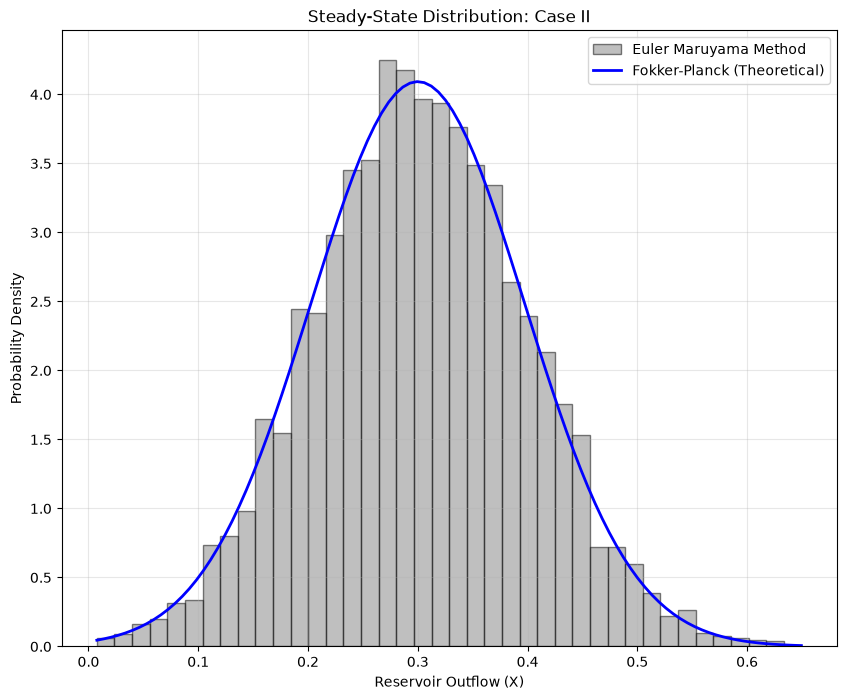

In [75]:
a_val_2 = 0.1 
p_case2 = Hydrology(
    c=0.0, e=0.0, 
    Phi=0.7,                             
    sigma_3=np.sqrt(0.1),                
    P=1.0, 
    E=0.0, 
    a_p=0.1,
    sigma_1=1.0, 
    sigma_2=0.0,                         
    alpha=0.0, beta=1.0, gamma=1.0,      
    A=a_val_2, B=0.0                        
)

X_paths_2 = EulerMaruyama(X0=0.5, p=p_case2, T=100.0, N=2000, M=5000)
fp_validate(X_paths_2, p_case2, case="II")

# Case III

The reservoir surface are scales linearly with the water volume. (The scaling factor $a$). This case is the most complex scenario, where the surface area grows as the water level rises. 


| **Parameter** | **Value**     | **Reason for Value**                                                               |
| ------------- | ------------- | ---------------------------------------------------------------------------------- |
| `c`           | 0.0           | The base surface area ratio is 0.                                                  |
| `e`           | `0.1 * a_val` | the surface area scales relative to outflow and this formula is given by the paper |
| `n`           | 1.0           | Ensures the reservoir's surface area scales linearly with water volume.            |
| `b_p`         | 1.0           | Paired with `n=1.0` to maintain exactly linear polynomial scaling.                 |


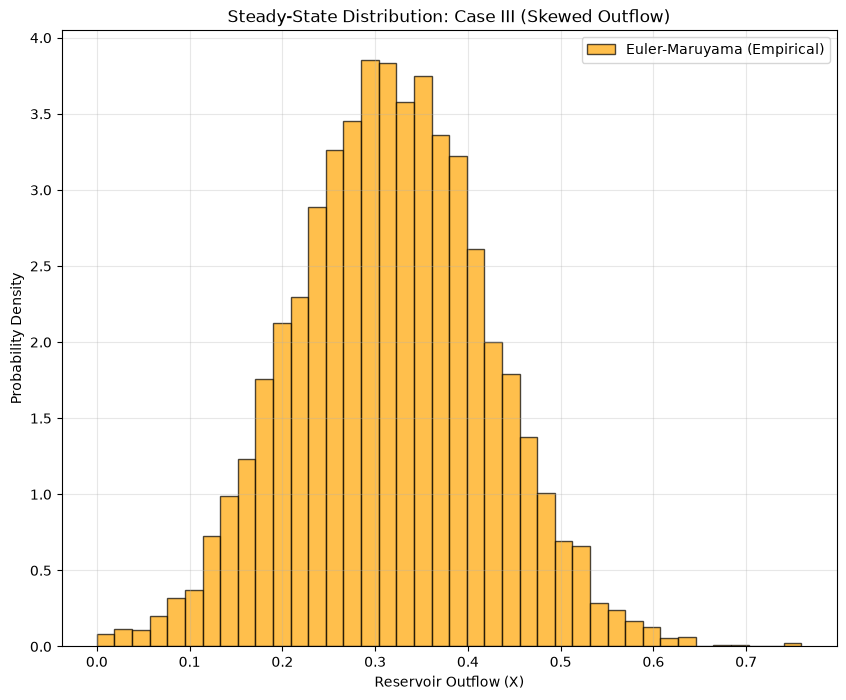

In [76]:
a_val = 0.1 # This means slightly skewed
p_case3 = Hydrology(
    c=0.0,                   
    e=0.1 * a_val,           
    Phi=0.7,                 
    sigma_3=np.sqrt(0.1),    
    P=1.0,                   
    E=0.1,                   
    a_p=a_val,
    sigma_1=1.0,             
    sigma_2=np.sqrt(0.1),    
    alpha=0.0,               
    beta=1.0,                
    gamma=1.0,               
    A=a_val,                 
    B=0.0,             
    n=1.0,            
    b_p=1.0            
)

X_paths_3 = EulerMaruyama(X0=0.5, p=p_case3, T=100.0, N=2000, M=5000)
final_states_3 = X_paths_3[-1, :]

# Plot the empirical histogram
plt.figure(figsize = (10,8))
plt.hist(final_states_3, bins=40, density=True, alpha=0.7, color='orange', 
         edgecolor='black', label='Euler-Maruyama (Empirical)')
plt.title('Steady-State Distribution: Case III (Skewed Outflow)')
plt.xlabel('Reservoir Outflow (X)')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [68]:
def validate_case3(a_val, empirical_data):
    # Coffecient from the paper
    K1 = -0.94 * a_val + 0.00345 * (a_val ** 2)
    K2 = 0.3 * a_val + 0.0055 * (a_val ** 2)
    K3 = 0.0069 * (a_val ** 2)
    K4 = 0.022 * (a_val ** 2)
    K5 = 0.19 * (a_val ** 2)
    # First moment (Mean)
    m1 = -K2 / K1
    # Second moment
    m2 = -((2 * K2 + K4) * m1 + K5) / (2 * K1 + K3)
    # Third moment
    m3 = -((K2 + K4) * m2 + K5 * m1) / (K1 + K3)

    theo_variance = m2 - (m1 ** 2)
    theo_std = np.sqrt(theo_variance)
    # Central 3rd moment for skewness: E[(X - \mu)^3] = E[X^3] - 3\mu E[X^2] + 2\mu^3
    central_m3 = m3 - 3 * m1 * m2 + 2 * (m1 ** 3)
    theo_skewness = central_m3 / (theo_std ** 3)
    theo_cv = theo_std / m1 # Coefficient of Variation

    # These are the empircal values after the simulations
    emp_mean = np.mean(empirical_data)
    emp_std = np.std(empirical_data)
    emp_skewness = sp_stats.skew(empirical_data)
    emp_cv = emp_std / emp_mean

    print(f"--- CASE III VALIDATION (a = {a_val}) ---")
    print(f"{'Statistic':<20} | {'Theoretical':<15} | {'Empirical':<15}")
    print("-" * 55)
    print(f"{'Mean':<20} | {m1:<15.4f} | {emp_mean:<15.4f}")
    print(f"{'Standard Deviation':<20} | {theo_std:<15.4f} | {emp_std:<15.4f}")
    print(f"{'Coeff of Variation':<20} | {theo_cv:<15.4f} | {emp_cv:<15.4f}")
    print(f"{'Skewness':<20} | {theo_skewness:<15.4f} | {emp_skewness:<15.4f}")

For increaseing values of a_val the skewness of the model will be apparenet

--- CASE III VALIDATION (a = 0.1) ---
Statistic            | Theoretical     | Empirical      
-------------------------------------------------------
Mean                 | 0.3199          | 0.3203         
Standard Deviation   | 0.1026          | 0.1012         
Coeff of Variation   | 0.3208          | 0.3159         
Skewness             | 0.0274          | -0.0327        


--- CASE III VALIDATION (a = 1.0) ---
Statistic            | Theoretical     | Empirical      
-------------------------------------------------------
Mean                 | 0.3262          | 0.4135         
Standard Deviation   | 0.3257          | 0.2668         
Coeff of Variation   | 0.9983          | 0.6451         
Skewness             | 0.0875          | 0.6061         


--- CASE III VALIDATION (a = 10.0) ---
Statistic            | Theoretical     | Empirical      
-------------------------------------------------------
Mean                 | 0.3920          | 0.8973         
Standard Deviation   | 1.0707

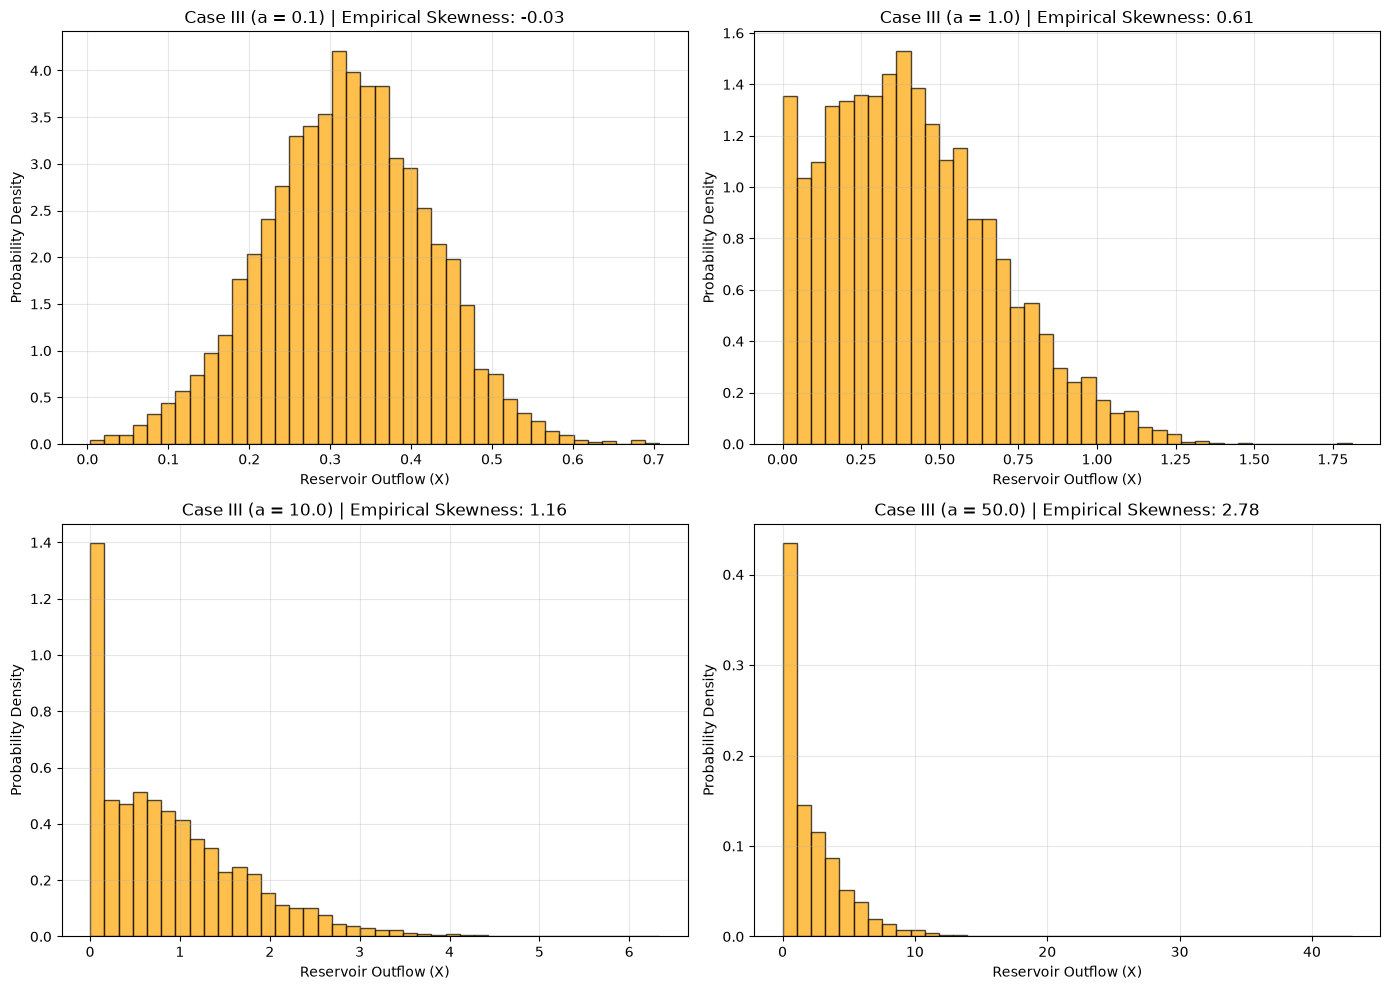

In [ ]:
# For different values we will find the skeweness
a_values = [0.1, 1.0, 10.0, 50.0]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for idx, a_val in enumerate(a_values):
    p_case3 = Hydrology(
        c=0.0, 
        e=0.1 * a_val, 
        Phi=0.7, 
        sigma_3=np.sqrt(0.1), 
        P=1.0, 
        E=0.1, 
        a_p=a_val,
        sigma_1=1.0, 
        sigma_2=np.sqrt(0.1), 
        alpha=0.0, 
        beta=1.0, 
        gamma=1.0, 
        A=a_val, 
        B=0.0, 
        n=1.0, 
        b_p=1.0
    )

    # Run Simulation
    X_paths_3 = EulerMaruyama(X0=0.5, p=p_case3, T=100.0, N=10000, M=5000)
    final_states_3 = X_paths_3[-1, :]

    validate_case3(a_val=a_val, empirical_data=final_states_3)
    print("\n")

    # Plot the histogram
    ax = axes[idx]
    ax.hist(final_states_3, bins=40, density=True, alpha=0.7, color='orange', edgecolor='black')
    
    current_skew = sp_stats.skew(final_states_3)
    ax.set_title(f'Case III (a = {a_val}) | Empirical Skewness: {current_skew:.2f}')
    ax.set_xlabel('Reservoir Outflow (X)')
    ax.set_ylabel('Probability Density')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

___

# A serires of Two Reservoirs
In a series, after the water from a Reservoir leaves it goes to another Reservoir.(outflow from Reservoir 1 ($X_1$) pours directly into Reservoir 2 ($X_2$) as an input.)

To model this, the Reservoir 1 operates exactly as it did before but for Reservoir 2 the inputed water will also come from the noisy Reservoir 1.

In the paper, the authors for $X_2$ have proposed this

$$ \frac{dX_2}{dt} = A \Big[ \psi(X_2)P + X_1 - \psi(X_2)E \Big] - B X_2^\gamma - A X_2^\beta $$

1. **The $+ X_1$ term**: The outflow from the first lake is now a direct input.
2. **No Abstractions on the Catchment**: In the paper's specific 2-reservoir setup, the secondary catchment abstractions ($\Phi$) are dropped from the input, leaving only the direct rainfall on the surface $\psi(X_2)P$ and the evaporation $\psi(X_2)E$.

In [77]:
def F_Res2(X1, X2, p: Hydrology):
    """
    Calculates the deterministic part of the reservoir level change for Reservoir 2.
    It takes X1 (the outflow of the first reservoir) as a direct input.
    """
    psi_x2 = psi(X2, p)
    
    # The inflow from Rain + Reservoir 1 Outflow - Evaporation
    F_in = psi_x2 * p.P + X1 - psi_x2 * p.E
    
    # Main dam outflow and seepage
    F_out = -p.A * (X2 ** p.beta) - p.B * (X2 ** p.gamma)
    
    return p.A * F_in + F_out

# Reservoir 2
For Reservoir 2 the surface are ratio is different to Reserovir 1 and the Also another input for water will be from Reservoir 1 otherwise every other parameters has the same effect on the Reservoir 2

According to Equation 50 in the paper, the noise terms (diffusion functions) for Reservoir 2 are:
1. *(Precipitation noise)* 
$$g_{1,2}(X_2) = \sigma_1 (e X_2 + Ac)$$
2. *(Catchment abstraction noise is zero for the second reservoir in this formulation)* 
$$g_{2,2}(X_2) = 0$$
3. *Evaporation Noise*
$$g_{3,2}(X_2) = -\sigma_2 (e X_2 + Ac)$$

In [78]:
def Calculate_g_Res2(X2, p: Hydrology):
    """
    Calculates the stochastic diffusion terms for Reservoir 2.
    """
    # From the paper's G(Y) matrix (Eq. 50)
    term = p.e * X2 + p.A * p.c
    g1 = p.sigma_1 * term
    g2 = 0.0
    g3 = -p.sigma_2 * term
    return [g1, g2, g3]

$$g_1' = \sigma_1 e$$

$$g_2' = 0$$

$$g_3' = -\sigma_2 e$$

In [79]:
def Calculate_g_prime_Res2(X2, p: Hydrology):
    """
    Calculates the derivatives of Reservoir 2's diffusion terms with respect to X2,
    needed for the Itô drift correction.
    """
    g1_prime = p.sigma_1 * p.e
    g2_prime = 0.0
    g3_prime = -p.sigma_2 * p.e
    return [g1_prime, g2_prime, g3_prime]

### Reservoir 2 Itô Drift

Just like before, because we are using the Euler-Maruyama numerical solver, we must combine the deterministic baseline ($F_{Res2}$) with the noise-induced Stratonovich correction term.

$$F_{1,\text{res2}} = \psi(X_2) P + X_1 - \psi(X_2) E$$

$$F_{2,\text{res2}} = -A X_2^{\beta} - B X_2^{\gamma}$$

$$F_{\text{deterministic}} = A F_{1,\text{res2}} + F_{2,\text{res2}}$$

$$\text{corrected term} = \frac{1}{2} \sum_{i=1}^{3} g_i(X_2) g_i'(X_2)$$

$$\text{Drift}_{\text{res2}} = F_{\text{deterministic}} + \text{corrected term}$$

In [80]:
def Drift_Res2(X1, X2, p: Hydrology):
    """
    Calculates the total Itô drift for Reservoir 2, combining deterministic inflow 
    from X1 and the noise-induced correction term.
    """
    psi_x2 = psi(X2, p)
    
    # Deterministic baseline F2 (Eq. 47)
    F1_res2 = psi_x2 * p.P + X1 - psi_x2 * p.E
    F2_res2 = -p.A * X2**p.beta - p.B * X2**p.gamma
    deterministic_F2 = p.A * F1_res2 + F2_res2
    
    # Itô correction term for Reservoir 2
    g_vals = Calculate_g_Res2(X2, p)
    g_prime_vals = Calculate_g_prime_Res2(X2, p)
    corrected_term = (1/2) * sum(g_val * g_prime_val for g_val, g_prime_val in zip(g_vals, g_prime_vals))
    
    return deterministic_F2 + corrected_term

# Combined Euler Maruyama Simulation
This is same as the single Reserovir but we add another variable for finding Reservoir 2

In [146]:
def EulerMaruyamaCascade(X0, p: Hydrology, T, N, M):
    """
    Simulates a series of two conceptual reservoirs operating in succession.
    Reservoir 1's outflow feeds directly into Reservoir 2.
    """
    floor_val=1e-8
    dt = T / N
    sqrt_dt = np.sqrt(dt)
    floor_val = 1e-8
    
    # Matrices to store paths for both reservoirs
    X1 = np.zeros((N, M))
    X2 = np.zeros((N, M))
    
    # Initial conditions
    X1[0, :] = X0
    X2[0, :] = X0

    for i in range(1, N):
        X1_prev = X1[i - 1, :]
        X2_prev = X2[i - 1, :]

        # Shared environmental noise for both lakes
        dW1, dW2, dW3 = np.random.normal(loc=0.0, scale=sqrt_dt, size=(3, M))

        # Reservor 1 Updation
        drift1 = Drift(X1_prev, p)
        g1_vals = Calculate_g(X1_prev, p)
        
        X1[i, :] = X1_prev + drift1 * dt + g1_vals[0] * dW1 + g1_vals[1] * dW2 + g1_vals[2] * dW3
        X1[i, :] = np.maximum(X1[i, :], floor_val)
        if floor_val is not None:
            X1[i, :] = np.maximum(X1[i, :], floor_val)

        # Reservor 2 Updation
        drift2 = Drift_Res2(X1_prev, X2_prev, p)
        g2_vals = Calculate_g_Res2(X2_prev, p)
        
        X2[i, :] = X2_prev + drift2 * dt + g2_vals[0] * dW1 + g2_vals[1] * dW2 + g2_vals[2] * dW3
        X2[i, :] = np.maximum(X2[i, :], floor_val)
        if floor_val is not None:
            X2[i, :] = np.maximum(X2[i, :], floor_val)

    return X1, X2

In [147]:
def plot_cascade_simulation(X1, X2, T, N):
  time = np.linspace(0, T, N)
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

  # Reservoir 1
  ax1.plot(time, X1[:, :10], color='grey', alpha=0.4)
  ax1.plot(
      time,
      np.mean(X1, axis=1),
      color='blue',
      label='Reservoir 1 Mean Outflow',
      linewidth=2,
  )
  ax1.set_title('Reservoir 1: Outflow Paths')
  ax1.set_xlabel('Time')
  ax1.set_ylabel('Outflow Level (X)')
  ax1.legend()
  ax1.grid(True, alpha=0.3)

  # Reservoir 2
  ax2.plot(time, X2[:, :10], color='grey', alpha=0.4)
  ax2.plot(
      time,
      np.mean(X2, axis=1),
      color='orange',
      label='Reservoir 2 Mean Outflow',
      linewidth=2,
  )
  ax2.set_title('Reservoir 2: Outflow Paths')
  ax2.set_xlabel('Time')
  ax2.legend()
  ax2.grid(True, alpha=0.3)

  fig.suptitle('Cascade of Two Reservoirs: Outflow Simulation', fontsize=14)
  plt.tight_layout()
  plt.show()

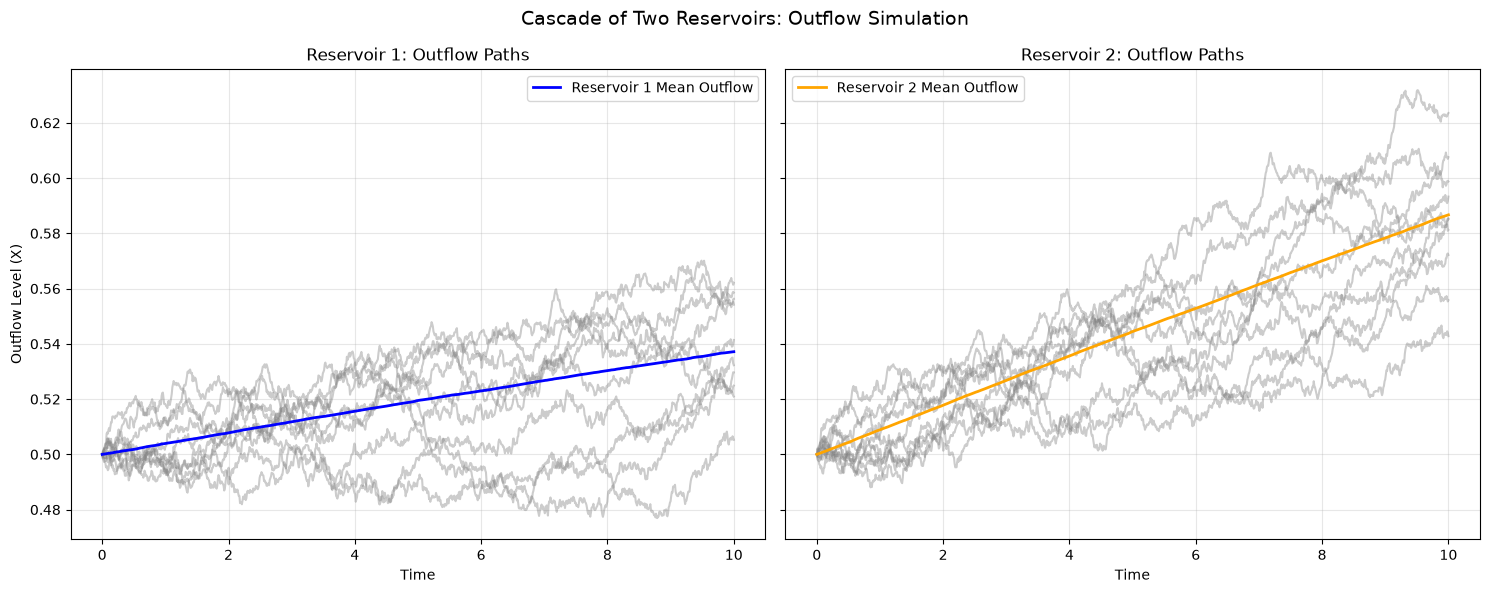

Reservoir 1 Mean (Theory: 0.90) | Empirical: 0.5372
Reservoir 2 Mean (Theory: 1.80) | Empirical: 0.5867


In [148]:
# Case I Parameters for the Cascade
p_cascade_case1 = Hydrology(
    c=1.0, e=0.0, Phi=0.0, sigma_3=0.0,  
    P=1.0, E=0.1, a_p=1.0,               
    sigma_1=1.0, sigma_2=np.sqrt(0.1),            
    alpha=0.0, beta=1.0, gamma=1.0,      
    A=0.01, B=0.0                         
)

# Run simulation
X1_paths, X2_paths = EulerMaruyamaCascade(X0=0.5, p=p_cascade_case1, T=10.0, N=1000, M=5000)

# Plot
plot_cascade_simulation(X1_paths, X2_paths, T=10.0, N=1000)

# Print final mean
print(f"Reservoir 1 Mean (Theory: 0.90) | Empirical: {np.mean(X1_paths[-1,]):.4f}")
print(f"Reservoir 2 Mean (Theory: 1.80) | Empirical: {np.mean(X2_paths[-1,]):.4f}")

# Analysis for Cascade of Reservoir

We will look at three extreme cases and evaluate how our model did.

## Case I
- Two reservoirs filling the whole catchment area (c=1, e=0, phi=0, E=0.1)

## Case II
- Two reservoirs of negligible area at the end of the catchment (c=0, e=0, E=0, phi=0.7)

## Case III
- Surface area varies linearly with outflow (c=0, e=0.1a)

In [149]:
def fp_validate_r2(Y2_ss, mean_th, var_th, title):
    """
    Compares empirical steady-state samples Y2[-1, :] against the exact
    Fokker-Planck Gaussian density.
    """
    std_th = np.sqrt(var_th)
    x = np.linspace(min(Y2_ss.min(), mean_th - 4 * std_th),
                    max(Y2_ss.max(), mean_th + 4 * std_th), 400)

    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.hist(Y2_ss, bins=50, density=True, alpha=0.6, color="steelblue",
            edgecolor="black", label="Simulated $y_2$")
    ax.plot(x, norm.pdf(x, loc=mean_th, scale=std_th), "r-", lw=2.2,
            label=f"Fokker–Planck $\\mathcal{{N}}({mean_th:.2f}, {var_th:.4f})$")

    ax.axvline(np.mean(Y2_ss), color="navy", ls="--", lw=1.2,
               label=f"Sim Mean = {np.mean(Y2_ss):.3f} (Var = {np.var(Y2_ss):.4f})")
    ax.set_title(title)
    ax.set_xlabel("$y_2$")
    ax.set_ylabel("Probability Density")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [150]:
def run_and_analyze_cascade(p_case, a_val, case_name, T=100.0, N=2000, M=5000):
  X1, X2 = EulerMaruyamaCascade(X0=0.5, p=p_case, T=T, N=N, M=M)

  # Compute mean and std for the final time step of both reservoirs
  stats = [(np.mean(X[-1]), np.std(X[-1])) for X in (X1, X2)]

  header = f"{'='*45}\nTWO-RESERVOIR CASCADE ANALYSIS: {case_name}\n{'='*45}"
  rows = "\n".join(
      f"Reservoir {i} {'Mean':<13} | {mean:<15.4f}\n"
      f"Reservoir {i} {'Std Dev':<13} | {std:<15.4f}"
      for i, (mean, std) in enumerate(stats, 1)
  )

  print(f"{header}\n{'Reservoir & Metric':<25} | {'Empirical':<15}\n{'-'*45}\n{rows}\n")
  return X1, X2

# Case I

In [151]:
p_cascade_case1 = Hydrology(
    c=1.0, e=0.0, Phi=0.0, sigma_3=0.0,
    P=1.0, E=0.1, a_p=1.0,
    sigma_1=1.0, sigma_2=np.sqrt(0.1),
    alpha=0.0, beta=1.0, gamma=1.0,
    A=1.0, B=0.0
)
X1_c1, X2_c1 = run_and_analyze_cascade(p_cascade_case1, a_val=1.0, case_name="Case I")


TWO-RESERVOIR CASCADE ANALYSIS: Case I
Reservoir & Metric        | Empirical      
---------------------------------------------
Reservoir 1 Mean          | 1.0219         
Reservoir 1 Std Dev       | 0.6502         
Reservoir 2 Mean          | 1.9676         
Reservoir 2 Std Dev       | 1.0515         



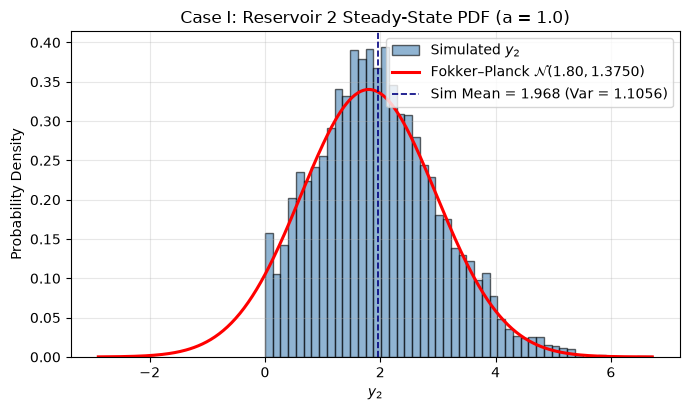

In [152]:
fp_validate_r2(
    X2_c1[-1, :],
    mean_th=2.0 * (p_cascade_case1.P - p_cascade_case1.E),
    var_th=1.25 * p_cascade_case1.a_p * (p_cascade_case1.sigma_1**2 + p_cascade_case1.sigma_2**2),
    title=f"Case I: Reservoir 2 Steady-State PDF (a = {a_val})"
)

# Case II

In [153]:
a_val_cascade2 = 0.1
p_cascade_case2 = Hydrology(
    c=0.0, e=0.0, 
    Phi=0.7,                             
    sigma_3=np.sqrt(0.1),                
    P=1.0, 
    E=0.0, 
    a_p=a_val_cascade2,
    sigma_1=1.0, 
    sigma_2=0.0,                         
    alpha=0.0, beta=1.0, gamma=1.0,      
    A=a_val_cascade2, B=0.0                        
)
X1_c2, X2_c2 = run_and_analyze_cascade(p_cascade_case2, a_val=0.1, case_name="Case II")


TWO-RESERVOIR CASCADE ANALYSIS: Case II
Reservoir & Metric        | Empirical      
---------------------------------------------
Reservoir 1 Mean          | 0.2992         
Reservoir 1 Std Dev       | 0.0955         
Reservoir 2 Mean          | 0.3000         
Reservoir 2 Std Dev       | 0.0675         



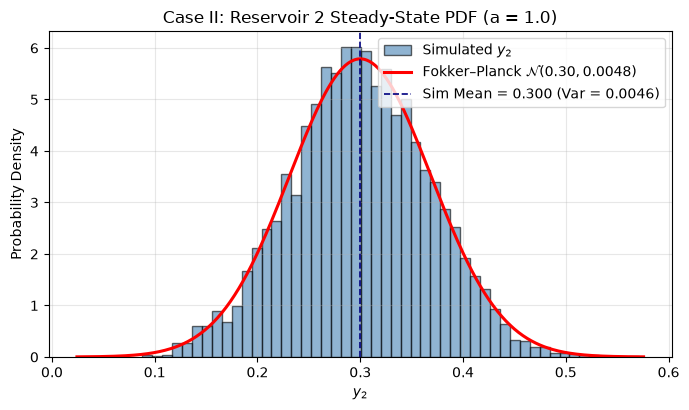

In [154]:
fp_validate_r2(
    X2_c2[-1, :],
    mean_th = (1.0 - p_cascade_case2.Phi) * p_cascade_case2.P,
    var_th = 0.25 * p_cascade_case2.a_p * (
    ((1.0 - p_cascade_case2.Phi)**2) * (p_cascade_case2.sigma_1**2)
    + (p_cascade_case2.P**2) * (p_cascade_case2.sigma_3**2)
    ),
    title=f"Case II: Reservoir 2 Steady-State PDF (a = {a_val})"
)

# Case III 

In [155]:
a_val_cascade3 = 0.1
p_cascade_case3 = Hydrology(
    c=0.0,                   
    e=0.1 * a_val_cascade3,           
    Phi=0.7,                 
    sigma_3=np.sqrt(0.1),    
    P=1.0,                   
    E=0.1,                   
    a_p=a_val_cascade3,
    sigma_1=1.0,             
    sigma_2=np.sqrt(0.1),    
    alpha=0.0,               
    beta=1.0,                
    gamma=1.0,               
    A=a_val_cascade3,                 
    B=0.0,             
    n=1.0,            
    b_p=1.0            
)
X1_c3, X2_c3 = run_and_analyze_cascade(p_cascade_case3, a_val=0.1, case_name="Case III")


TWO-RESERVOIR CASCADE ANALYSIS: Case III
Reservoir & Metric        | Empirical      
---------------------------------------------
Reservoir 1 Mean          | 0.3229         
Reservoir 1 Std Dev       | 0.1024         
Reservoir 2 Mean          | 0.3537         
Reservoir 2 Std Dev       | 0.0862         

